<a href="https://colab.research.google.com/github/javed005/Brain-Tumor-MRI/blob/main/Brain_Tumor_MRI_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Brain Tumor MRI Image Classification

Train a custom CNN, MobileNetV2 and EfficientNetB0, compare their measured results,
and download a submission ZIP with models, code, charts and a generated report.

**Before running:** choose **Runtime → Change runtime type → T4 GPU** or another
available GPU. Run the cells from top to bottom. This notebook contains the project
scripts, so you do not need to upload the source ZIP as well.

**Status:** this notebook has not been run on your MRI images. It includes no
trained weights or claimed MRI scores. Training creates those outputs.
This is an educational prototype without clinical validation.


In [3]:
# FIRST CELL — GOOGLE COLAB

from pathlib import Path
from importlib.metadata import version
import io
import os
import subprocess
import sys
import zipfile

PROJECT = Path("/content/Brain_Tumor_MRI_Submission")
required = [
    "brain_tumor_project.py",
    "mri_utils.py",
    "app.py",
    "make_submission.py",
]

# Restore the project scripts if this is a fresh runtime.
if not all((PROJECT / name).is_file() for name in required):
    from google.colab import files

    print("Upload Brain_Tumor_MRI_Source_Package.zip")
    uploaded = files.upload()
    archives = [
        name for name in uploaded
        if name.lower().endswith(".zip")
    ]

    if len(archives) != 1:
        raise ValueError("Select exactly one source-package ZIP.")

    destination = Path("/content").resolve()

    with zipfile.ZipFile(io.BytesIO(uploaded[archives[0]])) as archive:
        expected = {
            f"Brain_Tumor_MRI_Submission/{name}"
            for name in required
        }

        if not expected.issubset(set(archive.namelist())):
            raise ValueError(
                "Select Brain_Tumor_MRI_Source_Package.zip."
            )

        for member in archive.infolist():
            target = (destination / member.filename).resolve()

            if not target.is_relative_to(destination):
                raise ValueError("Unsafe path in the ZIP.")

            if (member.external_attr >> 16) & 0o170000 == 0o120000:
                raise ValueError("Symlinks are not supported.")

        archive.extractall(destination)

    del uploaded

os.chdir(PROJECT)

# Python 3.13 requires TensorFlow 2.20 or newer.
requirements = """tensorflow>=2.19,<2.22; python_version < "3.13"
tensorflow>=2.20,<2.22; python_version >= "3.13"
numpy>=1.26,<3
pandas>=2.2,<3
scikit-learn>=1.5,<2
matplotlib>=3.8,<4
Pillow>=10.4,<13
"""

(PROJECT / "requirements-colab.txt").write_text(
    requirements, encoding="utf-8"
)

(PROJECT / "requirements.txt").write_text(
    requirements + "streamlit>=1.50,<1.51\n",
    encoding="utf-8",
)

print("Python:", sys.version.split()[0])

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-r",
    "requirements-colab.txt",
])

if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

print("TensorFlow:", version("tensorflow"))
print("Setup ready. Run the dataset-upload cell next.")

Upload Brain_Tumor_MRI_Source_Package.zip


Saving Brain_Tumor_MRI_Source_Package.zip to Brain_Tumor_MRI_Source_Package.zip
Python: 3.13.15
TensorFlow: 2.21.0
Setup ready. Run the dataset-upload cell next.


## 2. Supply the assigned dataset

Download the complete folder from
[the assignment dataset](https://drive.google.com/drive/folders/1C9ww4JnZ2sh22I-hbt45OR16o4ljGxju?usp=sharing)
as a ZIP. In the next cell, upload the **dataset ZIP**, not the code ZIP.
The root must contain `train`, `valid` and `test`, each with `glioma`,
`meningioma`, `no_tumor` and `pituitary` subfolders.

Alternatively, add a shortcut to the dataset folder in **My Drive**, set
`DATA_SOURCE = 'drive'` and edit `DRIVE_DATASET_DIR` to that folder's mounted path.
The notebook then copies just the discovered dataset root to local Colab storage.

The original inventories list 1,695 training, 502 validation and 246 test images.
Repeated source families cross those splits; the training script removes them
and reports its actual retained counts. The source files are left unchanged.


In [4]:
# 2. Upload the dataset ZIP, or use a mounted Drive shortcut.
from google.colab import files, drive
import shutil
from mri_utils import safe_extract_zip, discover_dataset_root

DATA_SOURCE = 'zip_upload'  # Change to 'drive' only if you prefer a Drive shortcut.
DRIVE_DATASET_DIR = '/content/drive/MyDrive/Brain_Tumor_MRI_Dataset'
DATA_DIR = Path('/content/mri_dataset')

if DATA_SOURCE == 'zip_upload':
    uploaded = files.upload()
    archive_names = [name for name in uploaded if name.lower().endswith('.zip')]
    if not archive_names:
        raise ValueError('Upload the complete dataset ZIP downloaded from the assignment link.')
    # This directory contains only temporary dataset copies made by this notebook.
    if DATA_DIR.exists():
        shutil.rmtree(DATA_DIR)
    DATA_DIR.mkdir(parents=True)
    for name in archive_names:
        safe_extract_zip(name, DATA_DIR)
    del uploaded  # Release the upload byte buffers before GPU training.
elif DATA_SOURCE == 'drive':
    drive.mount('/content/drive')
    source_root = discover_dataset_root(DRIVE_DATASET_DIR)
    if DATA_DIR.exists():
        shutil.rmtree(DATA_DIR)
    shutil.copytree(source_root, DATA_DIR)
else:
    raise ValueError("DATA_SOURCE must be 'zip_upload' or 'drive'.")

DATA_ROOT = discover_dataset_root(DATA_DIR)
print('Dataset ready:', DATA_ROOT)


Saving Tumour-20261012T182232Z-1-001.zip to Tumour-20261012T182232Z-1-001.zip
Dataset ready: /content/mri_dataset/Tumour


## 3. Train all three models

Keep `weights=imagenet` for a real submission. The default is 12 initial epochs
and up to 3 fine-tuning epochs; early stopping may finish a model sooner.
For a shorter run you may choose 8 and 2, respectively, and judge its actual
validation results. GPU speed and availability determine completion time.

The selected deployment model is chosen from validation macro F1 **before**
any test predictions are computed. Test accuracy is not used for selection.
An existing nonempty `artifacts` directory is rejected to avoid mixing runs.


In [5]:
# 3. Real MRI training. Outputs remain available in the Colab Files panel.
import tensorflow as tf

EPOCHS = 12
FINE_TUNE_EPOCHS = 3
BATCH_SIZE = 32  # Use 16 if your GPU runs out of memory.
ALLOW_CPU = False  # CPU training can take much longer; enable only deliberately.

gpus = tf.config.list_physical_devices('GPU')
print('TensorFlow:', tf.__version__, 'GPU devices:', gpus)
if not gpus and not ALLOW_CPU:
    raise RuntimeError('Select a GPU in Runtime → Change runtime type, then rerun the notebook.')

command = [sys.executable, 'brain_tumor_project.py',
           '--data', str(DATA_ROOT), '--output', 'artifacts',
           '--epochs', str(EPOCHS), '--fine-tune-epochs', str(FINE_TUNE_EPOCHS),
           '--batch-size', str(BATCH_SIZE), '--image-size', '224', '--weights', 'imagenet']
subprocess.check_call(command)
print('Real-data training completed.')


TensorFlow: 2.21.0 GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Real-data training completed.


## 4. Inspect the measured results

The following cells show actual retained class counts, validation/test comparisons,
per-class test precision/recall/F1, confusion matrices and training curves.
The generated `REPORT.md` includes the measured comparison and limitations.


,split,class_name,images
0,train,glioma,238
1,train,meningioma,358
2,train,no_tumor,335
3,train,pituitary,438
4,validation,glioma,138
5,validation,meningioma,124
6,validation,no_tumor,99
7,validation,pituitary,118
8,test,glioma,77
9,test,meningioma,63


,model,validation_accuracy,validation_macro_f1,parameters,training_seconds,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,inference_ms,selected
0,custom_cnn,0.288100,0.111831,423268,218.903053,0.316872,0.079218,0.250000,0.120313,20.683376,False
1,mobilenet_v2,0.858038,0.856847,2422468,528.079775,0.847737,0.854074,0.857194,0.848299,208.177911,True
2,efficientnet_b0,0.839248,0.838424,4214055,509.276297,0.802469,0.803982,0.813028,0.802988,373.437227,False


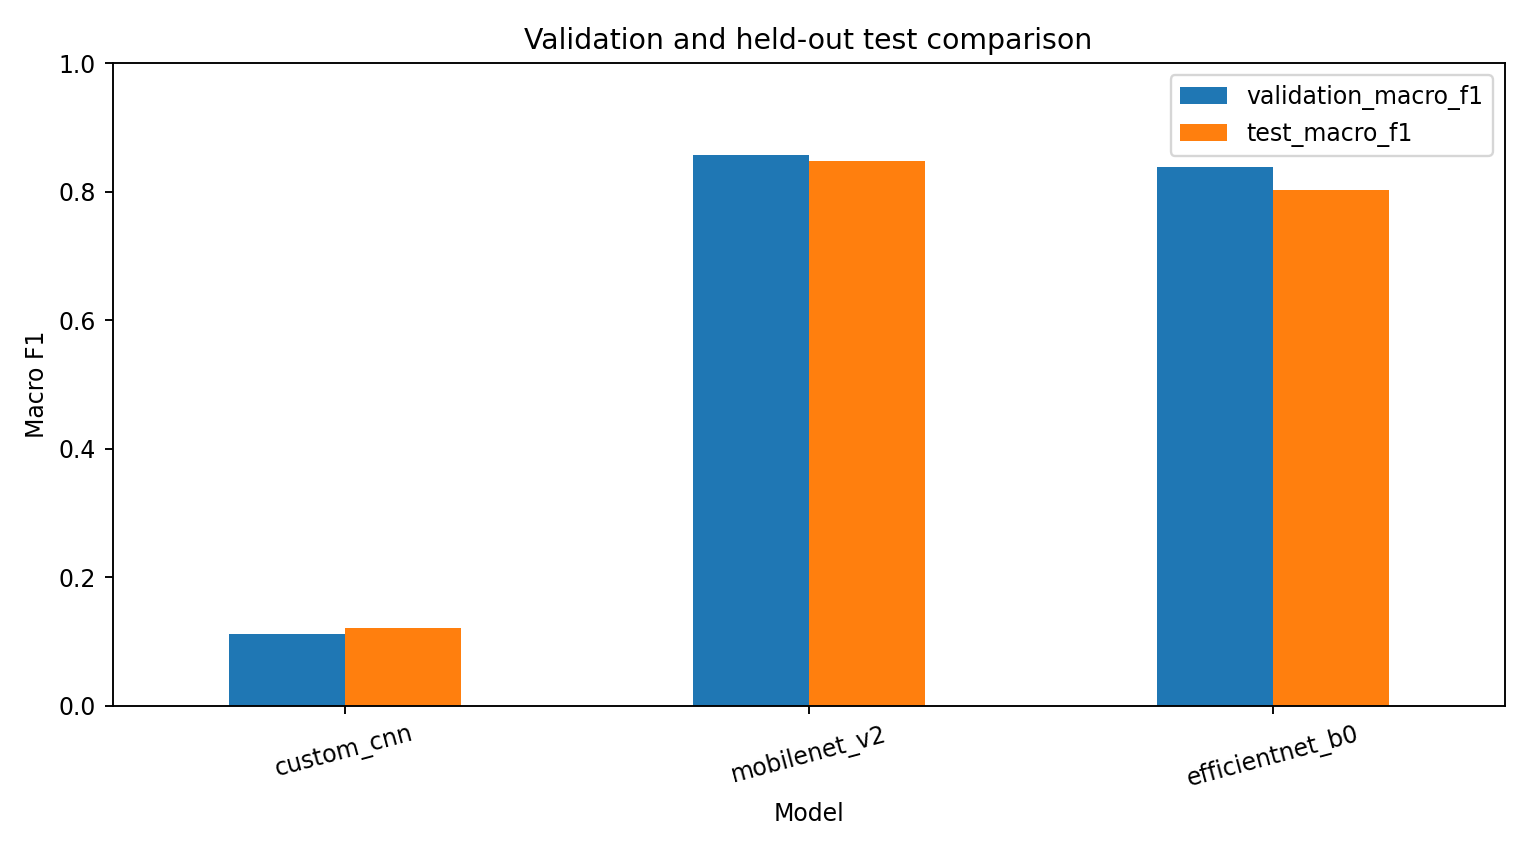

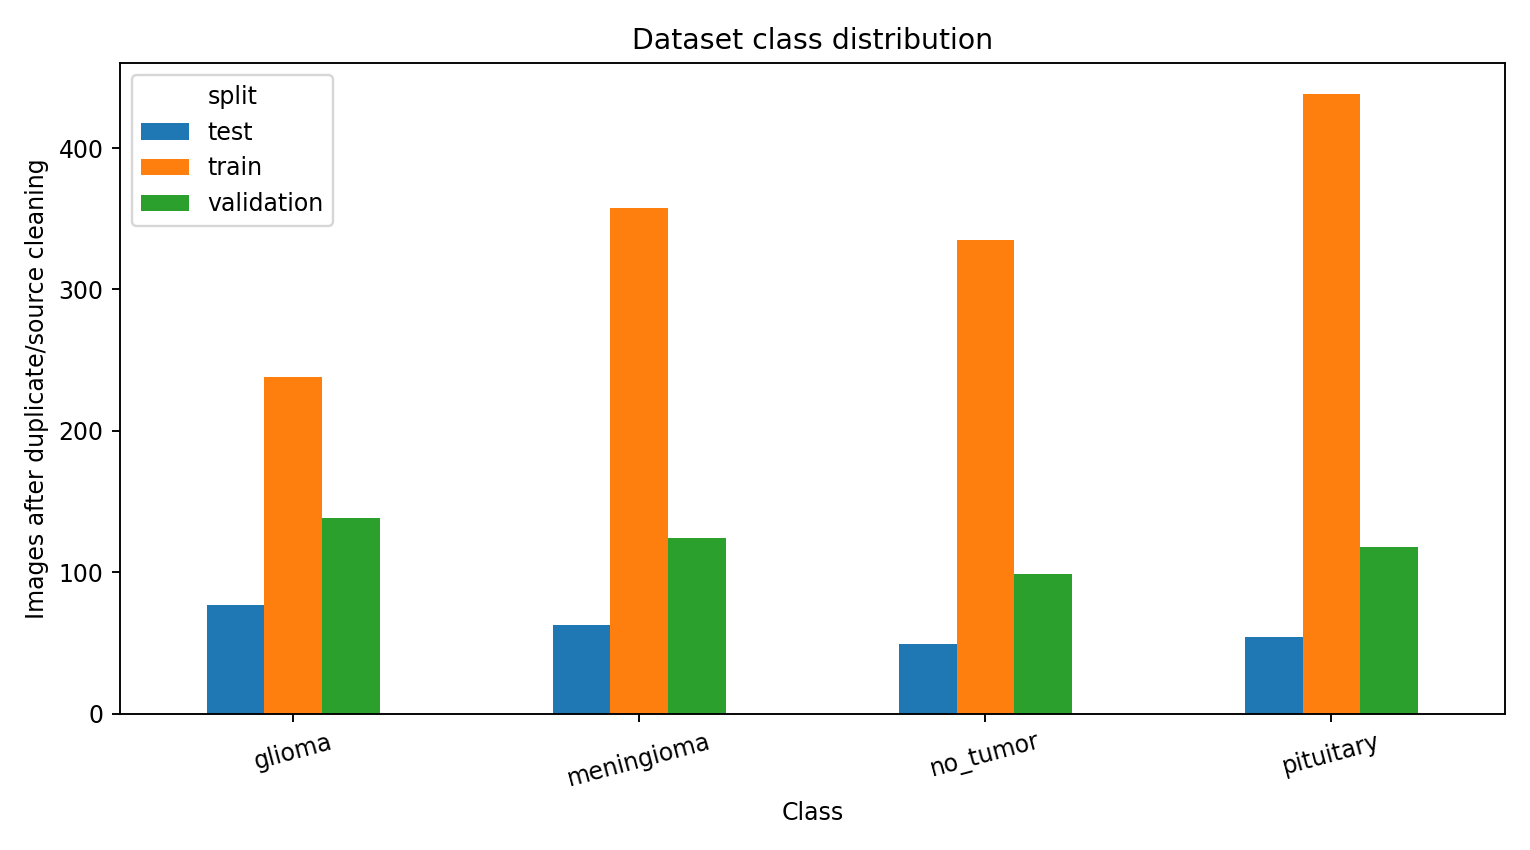


Model: custom_cnn
Test accuracy: 0.3169 Macro F1: 0.1203


,precision,recall,f1-score,support
glioma,0.316872,1.000000,0.481250,77.0
meningioma,0.000000,0.000000,0.000000,63.0
no_tumor,0.000000,0.000000,0.000000,49.0
pituitary,0.000000,0.000000,0.000000,54.0
macro avg,0.079218,0.250000,0.120313,243.0
weighted avg,0.100408,0.316872,0.152495,243.0


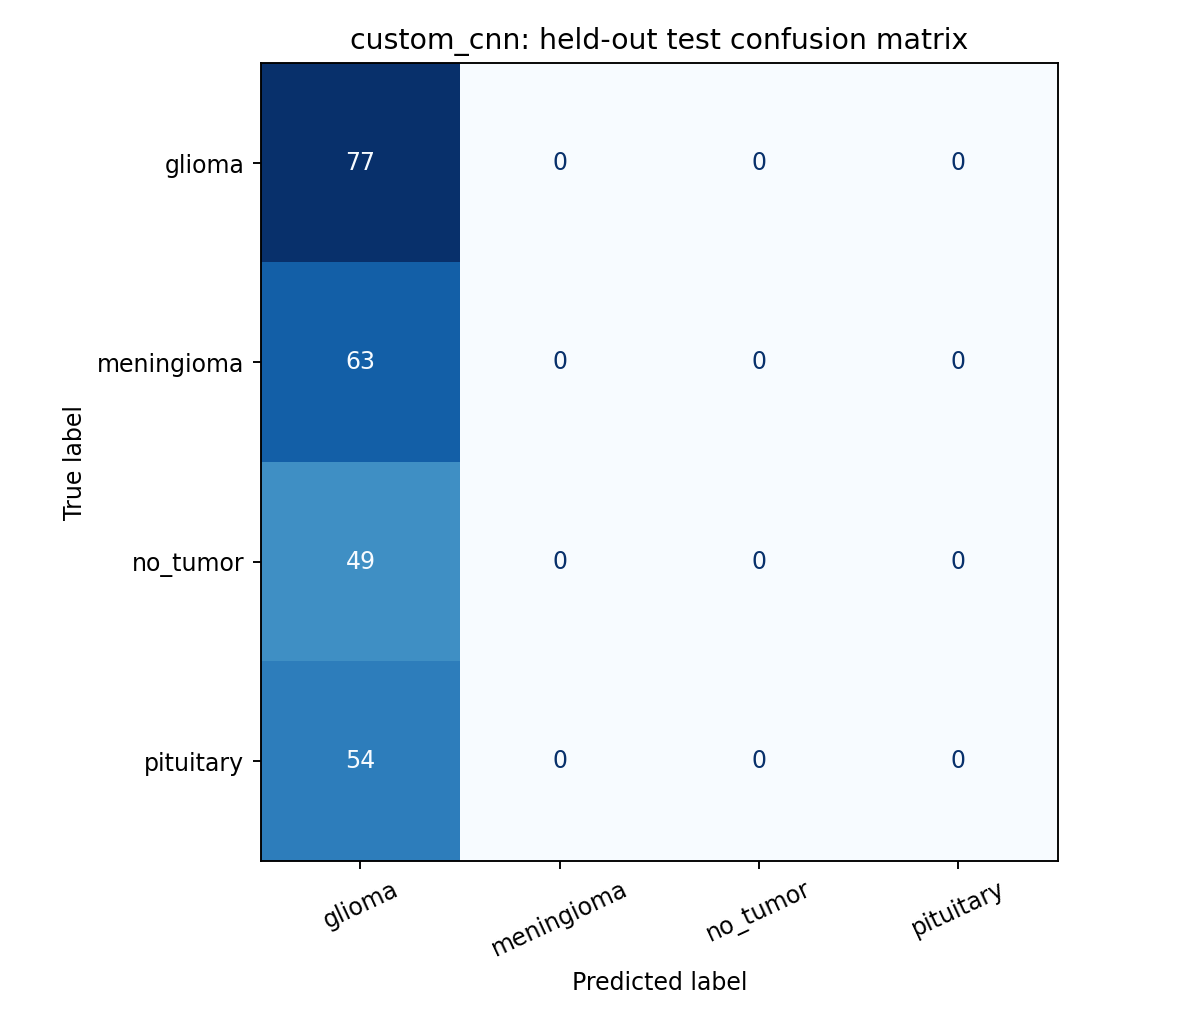

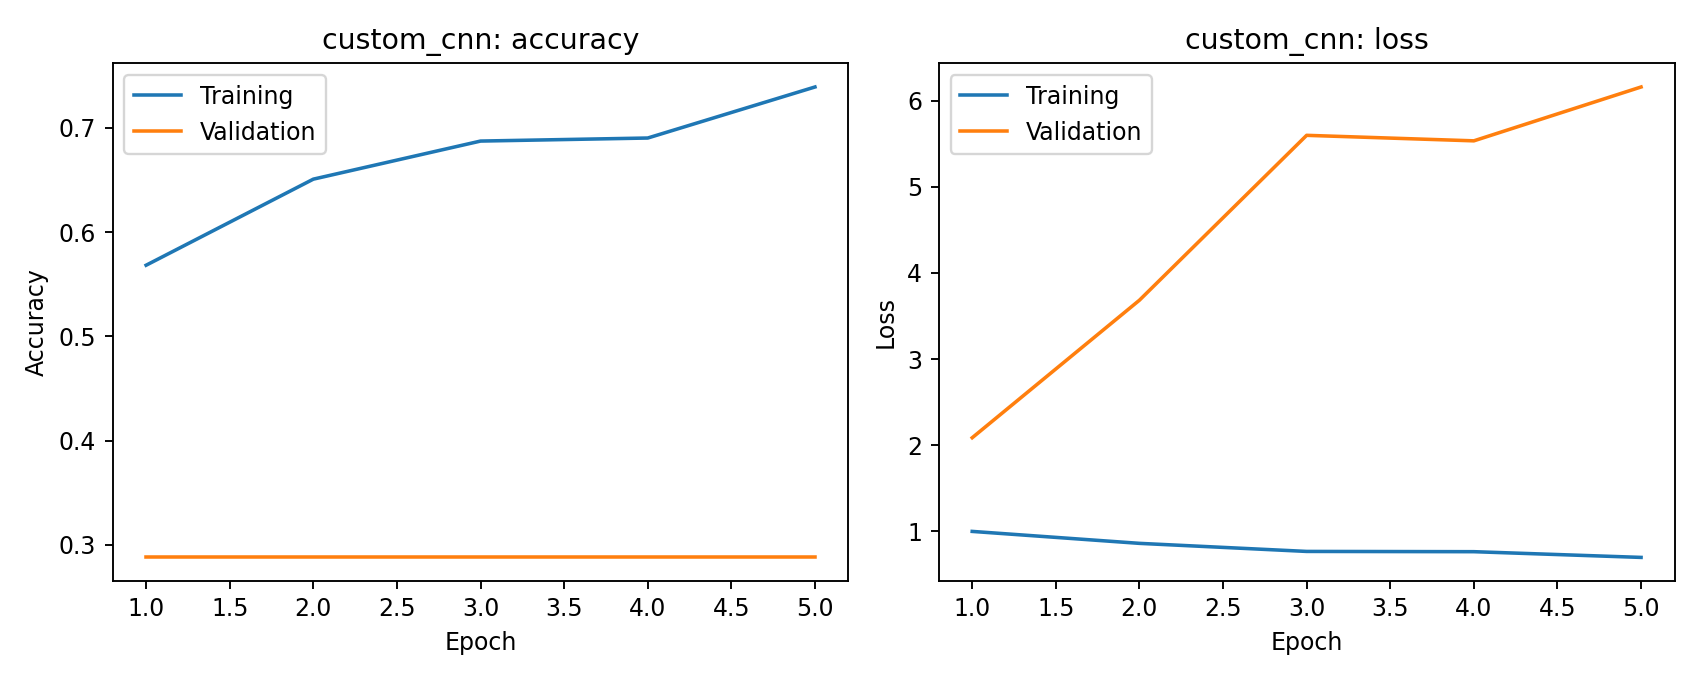


Model: mobilenet_v2
Test accuracy: 0.8477 Macro F1: 0.8483


,precision,recall,f1-score,support
glioma,0.984127,0.805195,0.885714,77.0
meningioma,0.796610,0.746032,0.770492,63.0
no_tumor,0.895833,0.877551,0.886598,49.0
pituitary,0.739726,1.000000,0.850394,54.0
macro avg,0.854074,0.857194,0.848299,243.0
weighted avg,0.863396,0.847737,0.848171,243.0


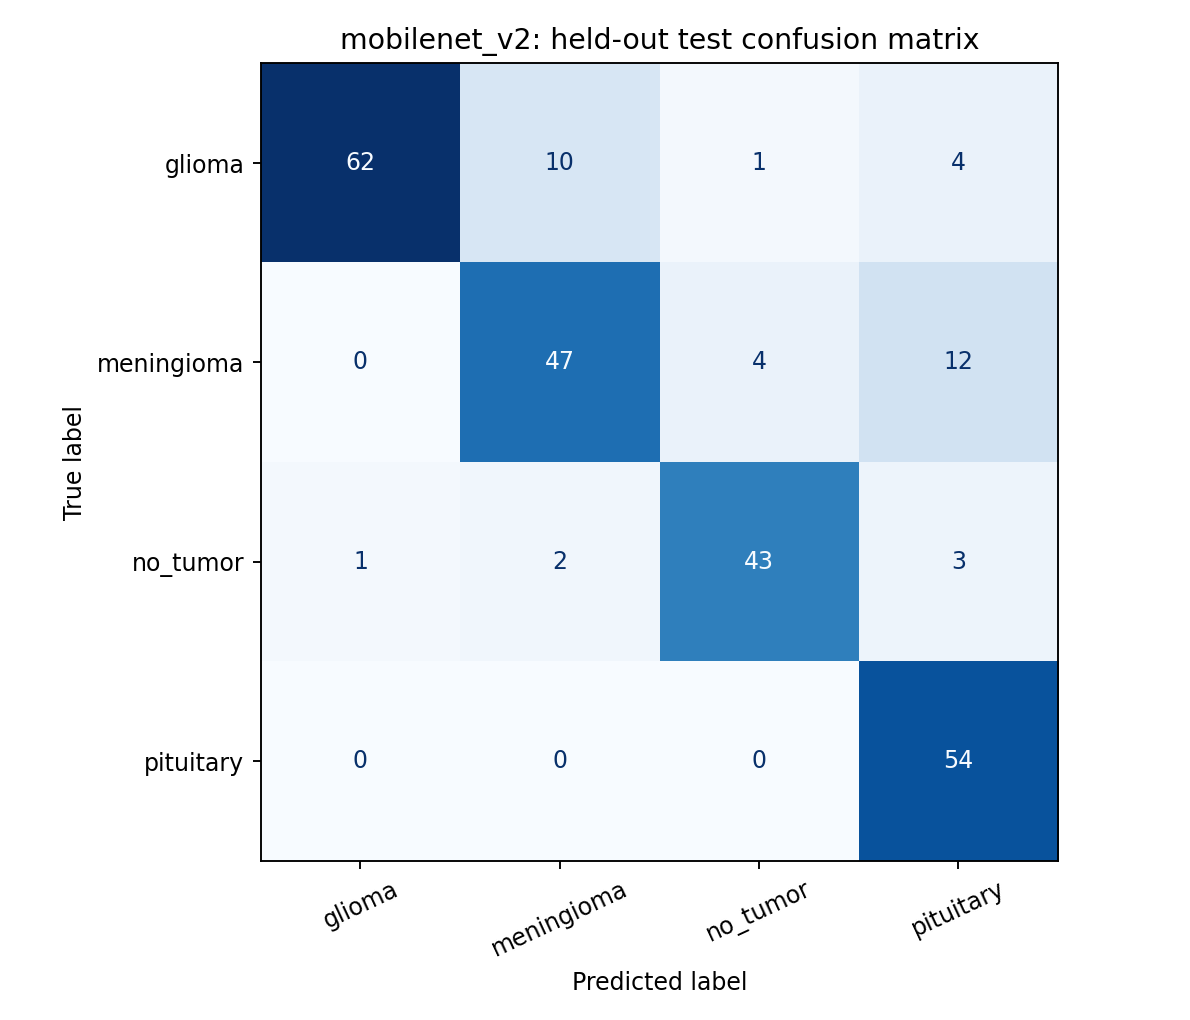

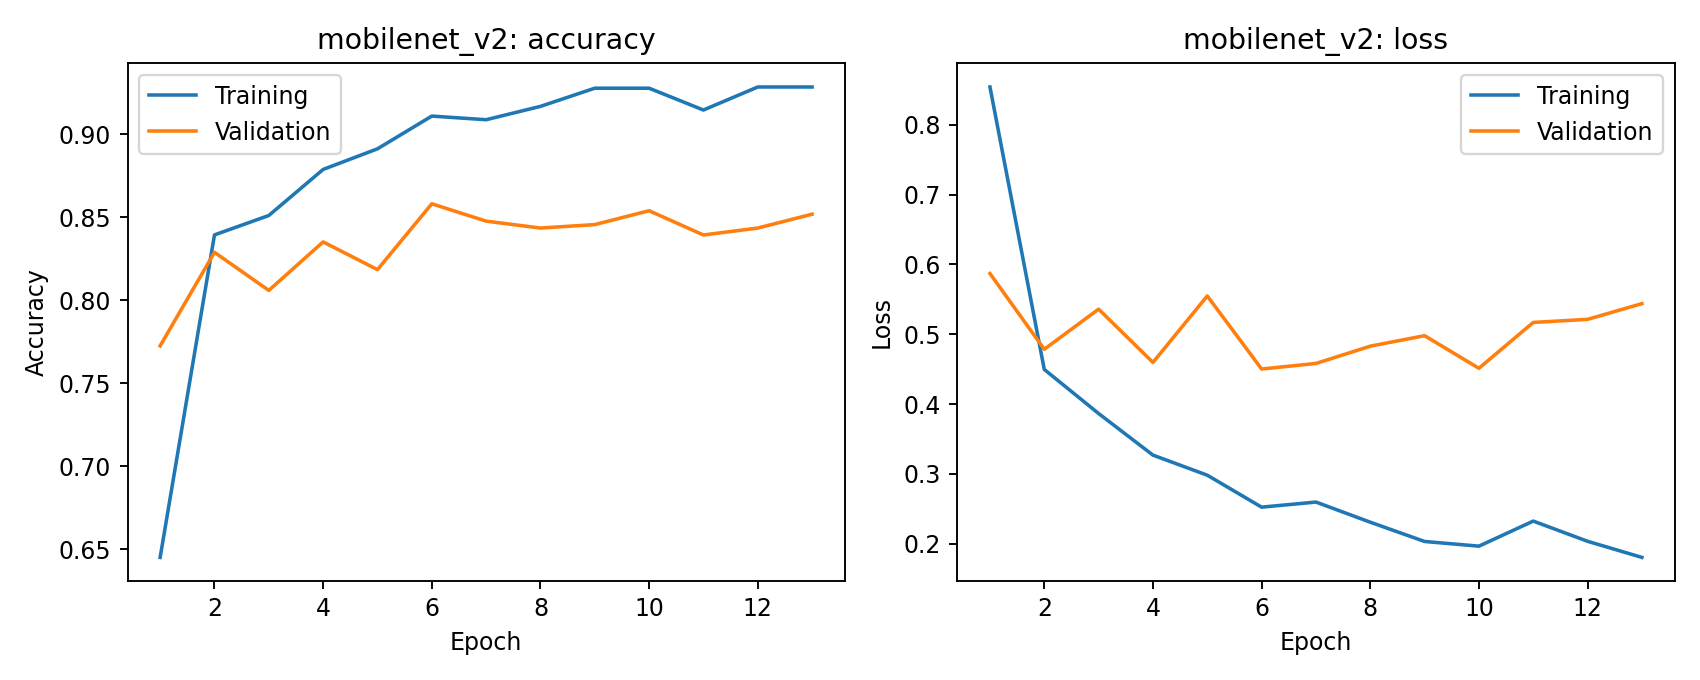


Model: efficientnet_b0
Test accuracy: 0.8025 Macro F1: 0.803


,precision,recall,f1-score,support
glioma,0.906250,0.753247,0.822695,77.0
meningioma,0.704918,0.682540,0.693548,63.0
no_tumor,0.833333,0.816327,0.824742,49.0
pituitary,0.771429,1.000000,0.870968,54.0
macro avg,0.803982,0.813028,0.802988,243.0
weighted avg,0.809389,0.802469,0.800353,243.0


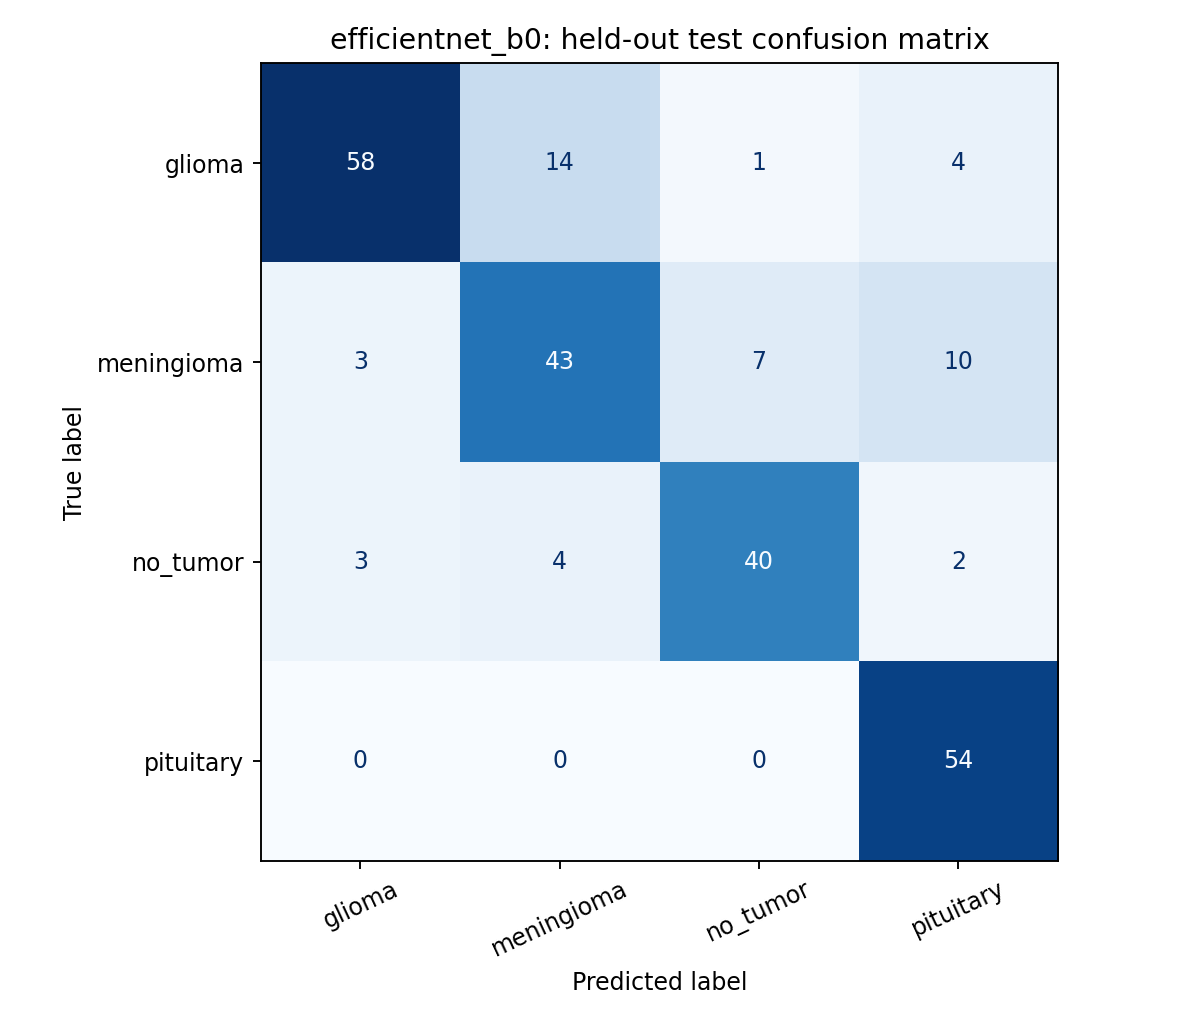

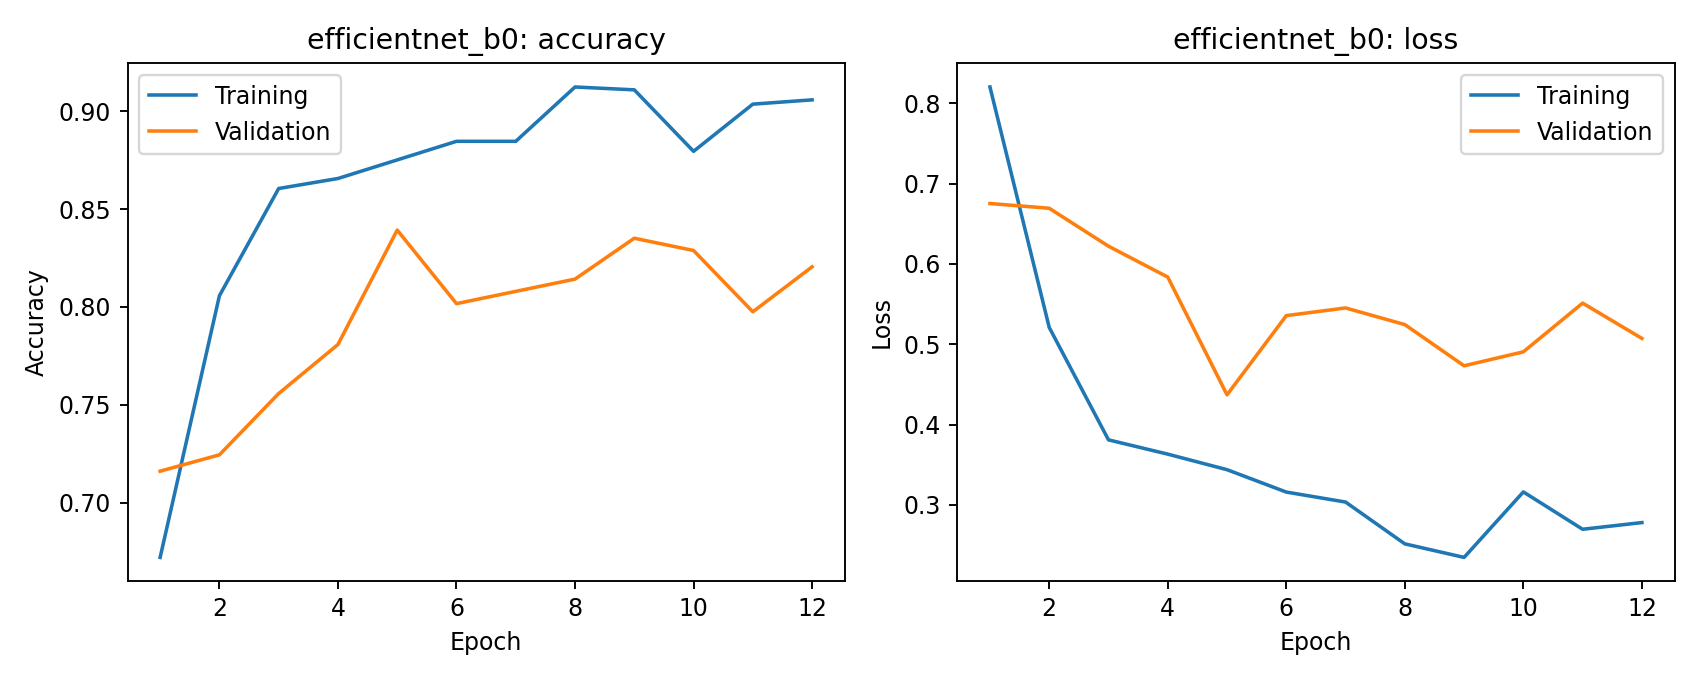

# Brain Tumor MRI Image Classification

## Objective

Compare a custom convolutional network with ImageNet transfer learning for four MRI image classes and provide a Streamlit research demonstration.

## Dataset and cleaning

Assigned source: https://drive.google.com/drive/folders/1C9ww4JnZ2sh22I-hbt45OR16o4ljGxju?usp=sharing

Classes: glioma, meningioma, no_tumor, pituitary.

Readable source images: 2443. Retained: 2091. Excluded: 352.

Exact decoded-pixel duplicates and Roboflow source-name families were grouped. One image per family was retained, prioritizing test, validation, then train. Conflicting-label families were excluded. See data_manifest.csv and excluded_images.csv.

## Method

Images are decoded as RGB, corrected for EXIF orientation, and resized with PIL bilinear interpolation. Training uses mild rotation, zoom, translation, horizontal flipping and brightness changes. Validation and test images are never augmented. Normalization is embedded in each saved model: custom CNN 0–1, MobileNetV2 −1–1, and EfficientNetB0's built-in preprocessing on raw 0–255 input.

Balanced class weights, dropout, batch normalization, early stopping, learning-rate reduction and best-validation-loss checkpoints are used. The transfer backbones are initially frozen; optional final-layer fine-tuning keeps batch normalization frozen.

## Model comparison

| Model | Validation accuracy | Validation macro F1 | Test accuracy | Test macro F1 | Parameters | Inference ms |
|---|---:|---:|---:|---:|---:|---:|
| custom_cnn | 0.2881 | 0.1118 | 0.3169 | 0.1203 | 423,268 | 20.68 |
| mobilenet_v2 | 0.8580 | 0.8568 | 0.8477 | 0.8483 | 2,422,468 | 208.18 |
| efficientnet_b0 | 0.8392 | 0.8384 | 0.8025 | 0.8030 | 4,214,055 | 373.44 |

Selected deployment model: **mobilenet_v2**, chosen by validation macro F1 (validation accuracy, then parameter count break ties) before computing test metrics.

Test accuracy, macro precision, macro recall, macro F1, per-class results and confusion matrices are stored in the results files. Latency is the mean of ten warmed single-image forward passes on the recorded runtime; it is not an end-to-end web latency measurement.

![Model comparison](model_comparison.png)

![Class distribution](class_distribution.png)

## Deployment

Run `streamlit run app.py` from the project folder. The application reads artifacts/deployment/model.keras and its metadata, and uses the same RGB and resize code as training. It shows all four softmax scores; these are not calibrated clinical probabilities.

## Limitations

This is an image classification educational prototype, not a diagnostic or triage system. Patient IDs are not supplied, so patient-level independence cannot be verified. The cleaning does not detect every near duplicate. Results on this small curated dataset do not establish performance on other hospitals, scanners, populations, MRI sequences, or non-MRI uploads. A no_tumor prediction is not evidence that a person is tumor-free. Independent patient-level external validation, probability calibration, and clinical review would be needed before any medical use.

## Reproducibility

See run_config.json, environment.json, class_names.json, the retained-image manifest, training history CSVs, and test_predictions.csv. A fixed seed improves repeatability; hardware and library differences can still change training results.

## Dataset attribution

The supplied README identifies Labeled MRI Brain Tumor Dataset Version 1 by the Roboflow user Ali Rostami and CC BY 4.0. Original page: https://universe.roboflow.com/ali-rostami/labeled-mri-brain-tumor-dataset . The provider's labeling statements have not been independently verified.


In [6]:
# 4. Read the results from this run.
import json
import pandas as pd
from IPython.display import display, Image as DisplayImage, Markdown

RESULTS = PROJECT / 'artifacts' / 'results'
display(pd.read_csv(RESULTS / 'class_counts.csv'))
comparison = pd.read_csv(RESULTS / 'model_comparison.csv')
display(comparison)
display(DisplayImage(filename=str(RESULTS / 'model_comparison.png')))
display(DisplayImage(filename=str(RESULTS / 'class_distribution.png')))
for model_name in ['custom_cnn', 'mobilenet_v2', 'efficientnet_b0']:
    metrics = json.loads((RESULTS / f'{model_name}_test_metrics.json').read_text())
    print()
    print('Model:', model_name)
    print('Test accuracy:', round(metrics['accuracy'], 4),
          'Macro F1:', round(metrics['macro_f1'], 4))
    report = pd.DataFrame({name:values for name, values in metrics['classification_report'].items()
                           if isinstance(values, dict)}).transpose()
    display(report)
    display(DisplayImage(filename=str(RESULTS / f'{model_name}_confusion_matrix.png')))
    display(DisplayImage(filename=str(RESULTS / f'{model_name}_training_curves.png')))
display(Markdown((RESULTS / 'REPORT.md').read_text(encoding='utf-8')))


## 5. Download the trained submission

The ZIP will contain the project code, the three required `.h5` models, selected
native `.keras` deployment model, metadata, measured results, charts and report.
Dataset images and redundant native model copies are excluded to reduce size.

Also download your **executed notebook** through **File → Download → Download .ipynb**.
Publish the code to your own public GitHub repository and include its link.
The notebook does not create or publish a repository automatically.


In [7]:
import sys
import subprocess
from pathlib import Path
from google.colab import files

project = Path("/content/Brain_Tumor_MRI_Submission")
archive = Path("/content/Brain_Tumor_MRI_Trained_Submission.zip")

if not (project / "make_submission.py").is_file():
    print("Project files are missing. Run Cell 1 (setup) first.")

elif not (project / "artifacts").is_dir():
    print("Training outputs are missing. Complete the training cell "
          "or restore your saved artifacts folder first.")

else:
    subprocess.run(
        [
            sys.executable, "make_submission.py",
            "--artifacts", "artifacts",
            "--output", str(archive)
        ],
        cwd=str(project),
        check=True
    )
    files.download(str(archive))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Run Streamlit on your computer

Extract the trained ZIP, open its project directory in a terminal, and run:

```bash
python -m pip install -r requirements.txt
streamlit run app.py
```

Open the local URL printed by Streamlit. Upload a brain MRI JPG/PNG to show the
predicted image class and all model scores, and open the Evaluation results tab.
The app is an educational research demo, not a diagnosis or treatment tool.
